# Photothermal PINN — Revision 1

In [11]:
import os, io, functools, hashlib
from contextlib import redirect_stdout
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares

from network import NetDiscovery, np_to_th, DEVICE
from diff_equations import grad

# a trained PINN is saved in cache/ and loaded the next time (same data and settings); set USE_CACHE = False to train again
USE_CACHE = True
CACHE_VERSION = 1
CACHE_DIR = "cache"
os.makedirs(CACHE_DIR, exist_ok=True)


def cache_file(name, *parts):
    h = hashlib.md5(str(CACHE_VERSION).encode())
    for p in parts:
        h.update(np.asarray(p, dtype=float).tobytes() if isinstance(p, np.ndarray) else repr(p).encode())
    return os.path.join(CACHE_DIR, f"{name}_{h.hexdigest()}.pt")


Tenv_true, a_true, tau_true = 25.0, 0.05, 300.0        # synthetic data: ambient temperature, heating rate, time constant


def heating_cooling(t, a, tau, t_off, Tenv=25.0):
    theta_off = a * tau * (1 - np.exp(-t_off / tau))
    return Tenv + np.where(t < t_off, a * tau * (1 - np.exp(-t / tau)), theta_off * np.exp(-(t - t_off) / tau))


def make_experiment(t_off_e, t_end, dt=10, noise=0.1, seed=0):
    rng = np.random.default_rng(seed)
    t_e = np.arange(0, t_end + dt / 2, dt)
    T_e = functools.partial(heating_cooling, a=a_true, tau=tau_true, t_off=t_off_e, Tenv=Tenv_true)(t_e)
    return t_e, T_e + rng.normal(0, noise, len(t_e))

EXPERIMENTS = {
    "full  (heat 5τ, cool 5τ)":  dict(t_off_e=5 * tau_true, t_end=10 * tau_true),
    "short (heat 1τ, cool 2τ)": dict(t_off_e=1 * tau_true, t_end= 3 * tau_true),
}

REAL_DATASETS = {      # file, optional nanoparticle name, laser switch-off time and ambient temperature of each curve
    "DS1":  dict(file="real_data/gnr_10x38_20ugml_NIR_laser.csv", t_off=900.0, Tenv=25.0),
    "DS2a": dict(file="real_data/gnr_10x41_peg_bare_808nm_2W.csv", nanoparticle="B-GNR_10x41nm_808nm_2W", t_off=1799.2, Tenv=25.47),
    "DS2b": dict(file="real_data/gnr_10x41_peg_bare_808nm_2W.csv", nanoparticle="PEG-GNR_10x41nm_808nm_2W", t_off=1799.2, Tenv=25.34),
    "DS3":  dict(file="real_data/aunr_785nm_1p2Wcm2_pmc13028931.csv", t_off=1347.4, Tenv=23.85),
    "DS4":  dict(file="real_data/aunrsi_785nm_1p2Wcm2_pmc13028931.csv", t_off=1255.1, Tenv=24.15),
}
REAL_BY_LABEL = REAL_DATASETS
DIAG_CURVE = "DS2b"


def load_real(ds):
    df = pd.read_csv(ds["file"])
    if "nanoparticle" in ds:
        df = df[df["nanoparticle"] == ds["nanoparticle"]]
    return df["time_s"].values.astype(float), df["T_C"].values.astype(float)

def simulate_loss(t, a_, f, t_off_):
    # numerical solution of dθ/dt = a L(t) - f(θ), θ(0) = 0
    rhs = lambda tt, y: [a_ * (tt < t_off_) - f(max(y[0], 0.0))]
    return solve_ivp(rhs, (0, t.max()), [0.0], t_eval=t, max_step=5.0, rtol=1e-8, atol=1e-10).y[0]


def single_tau_fit(t, th, t_off_):
    res = least_squares(lambda p: simulate_loss(t, p[0], lambda x: p[1] * x, t_off_) - th, [0.05, 3e-3],
                        bounds=([1e-5, 1e-6], [5, 1]), diff_step=1e-3, x_scale="jac")
    return res.x, np.sqrt(np.mean(res.fun ** 2))

In [12]:
class PhotothermalPINN(NetDiscovery):
    """PINN for discovering (a, τ) from photothermal heating–cooling data."""

    def __init__(self, t_off_hat, switch_input=True,
                 n_units=100, epochs=3000, data_loss=nn.MSELoss(),
                 lr=3e-3, physics_loss=None, data_weight=1.0, physics_weight=1.0):
        n_in = 2 if switch_input else 1
        super().__init__(input_dim=n_in, output_dim=1,
                         n_units=n_units, epochs=epochs,
                         data_loss=data_loss, lr=lr,
                         physics_loss=physics_loss,
                         data_weight=data_weight, physics_weight=physics_weight)

        # Replace ReLU activations with tanh for smooth ODE gradients
        for i, layer in enumerate(self.layers):
            if isinstance(layer, nn.ReLU):
                self.layers[i] = nn.Tanh()

        self.t_off_hat    = t_off_hat
        self.switch_input = switch_input
        self.a            = nn.Parameter(data=torch.tensor([0.]))

    def forward(self, t):
        if self.switch_input:
            t = torch.cat([t, torch.relu(t - self.t_off_hat)], dim=1)
        return self.out(self.layers(t))


def train_photothermal(t_, T_, t_off_, Tenv_=Tenv_true,
                       switch_input=True, data_weight=1.0, physics_weight=1.0,
                       adam_epochs=3000, lbfgs_iters=300, seed=0, return_fit=False, log=None):
    """Train PhotothermalPINN and return (a_est, tau_est), plus the network's fitted T if return_fit."""
    torch.manual_seed(seed)

    # Normalise inputs to [0, 1]
    t_scale = float(t_.max())
    T_scale = float(max((T_ - Tenv_).max(), 1e-3))
    t_hat, theta_hat = t_ / t_scale, (T_ - Tenv_) / T_scale
    t_off_hat    = t_off_ / t_scale

    def physics_loss(model):
        t_col = torch.linspace(0, 1, 800).view(-1, 1).requires_grad_(True).to(DEVICE)
        laser = (t_col < t_off_hat).float()
        temps = model(t_col)
        dT    = grad(temps, t_col)[0]
        pde   = model.a * laser - model.kappa * temps - dT
        ic    = model(torch.zeros(1, 1).to(DEVICE)).pow(2).mean()
        return torch.mean(pde ** 2) + ic

    model = PhotothermalPINN(t_off_hat, switch_input=switch_input,
                              physics_loss=physics_loss,
                              data_weight=data_weight, physics_weight=physics_weight,
                              epochs=adam_epochs, lr=3e-3).to(DEVICE)   # same device as the data
    Xt_ = np_to_th(t_hat.reshape(-1, 1))
    yt_ = np_to_th(theta_hat.reshape(-1, 1))
    cache_path = cache_file("photothermal", t_, T_, t_off_, Tenv_, switch_input, data_weight, physics_weight, adam_epochs, lbfgs_iters, seed)
    if USE_CACHE and log is None and os.path.exists(cache_path):
        model.load_state_dict(torch.load(cache_path, map_location=DEVICE))      # trained before: no training
    else:
        if log is not None:
            log.start(model, T_scale / t_scale)
        model.fit(t_hat.reshape(-1, 1), theta_hat.reshape(-1, 1),
                  on_step=None if log is None else lambda ep, d, p: log.record("Adam", d, p))
        if log is not None:
            log.end_adam()

        # L-BFGS fine-tuning
        opt = torch.optim.LBFGS(model.parameters(), lr=1.0,
                                  max_iter=lbfgs_iters, line_search_fn='strong_wolfe')
        def _closure():
            opt.zero_grad()
            data_term = model.data_loss(yt_, model(Xt_))
            physics_term = physics_loss(model)
            l = data_weight * data_term + physics_weight * physics_term
            l.backward()
            if log is not None:
                log.record("L-BFGS", data_term, physics_term)
            return l
        opt.step(_closure)
        if log is not None:
            log.finish(opt)
        if USE_CACHE and log is None:
            torch.save(model.state_dict(), cache_path)

    a_est, tau_est = model.a.item() * T_scale / t_scale, t_scale / model.kappa.item()
    if return_fit:   # the network's own output at the data times, in °C
        fit = model(Xt_).detach().cpu().numpy().ravel() * T_scale + Tenv_
        return a_est, tau_est, fit
    return a_est, tau_est


class LossNet(nn.Module):
    # f(θ) = θ·softplus(h(θ)): zero at ambient temperature, positive above it
    def __init__(self, n=20):
        super().__init__()
        self.h = nn.Sequential(nn.Linear(1, n), nn.Tanh(), nn.Linear(n, n), nn.Tanh(), nn.Linear(n, 1))

    def forward(self, th):
        return th * nn.functional.softplus(self.h(th))


class LossPINN(nn.Module):
    # temperature network with the switch input of Section 5, plus the learned loss law and the heating rate a
    def __init__(self, t_off_hat, n_units=100):
        super().__init__()
        self.t_off_hat = t_off_hat
        layers, d = [], 2
        for _ in range(4):
            layers += [nn.Linear(d, n_units), nn.Tanh()]
            d = n_units
        self.body = nn.Sequential(*layers, nn.Linear(n_units, 1))
        self.loss_law = LossNet()
        self.a = nn.Parameter(torch.tensor([1.0]))

    def forward(self, t):
        return self.body(torch.cat([t, torch.relu(t - self.t_off_hat)], dim=1))


def train_loss_pinn(t, th, t_off_, adam_epochs=8000, lbfgs_iters=1000, data_weight=1.0, physics_weight=1.0, seed=0, n_units=100, return_terms=False, log=None):
    torch.manual_seed(seed)
    t_scale, T_scale = float(t.max()), float(th.max())
    t_hat = np_to_th(t / t_scale); theta_hat = np_to_th(th / T_scale)
    model = LossPINN(t_off_ / t_scale, n_units=n_units).to(DEVICE)
    t_col = torch.linspace(0, 1, 800).view(-1, 1).to(DEVICE).requires_grad_(True)
    laser = (t_col < t_off_ / t_scale).float()

    def losses():                      # data loss and physics loss (ODE residual + initial condition)
        th_c = model(t_col)
        dth = grad(th_c, t_col)[0]
        res = dth - model.a * laser + model.loss_law(th_c)
        ic = model(torch.zeros(1, 1).to(DEVICE)).pow(2).mean()
        return ((model(t_hat) - theta_hat) ** 2).mean(), (res ** 2).mean() + ic

    def total_loss(phase):
        data_loss, physics_loss = losses()
        l = data_weight * data_loss + physics_weight * physics_loss
        l.backward()
        if log is not None:
            log.record(phase, data_loss, physics_loss)
        return l

    cache_path = cache_file("lossnet", t, th, t_off_, adam_epochs, lbfgs_iters, data_weight, physics_weight, seed, n_units)
    if USE_CACHE and log is None and os.path.exists(cache_path):
        model.load_state_dict(torch.load(cache_path, map_location=DEVICE))      # trained before: no training
    else:
        if log is not None:
            log.start(model, T_scale / t_scale)
        opt = torch.optim.Adam(model.parameters(), lr=3e-3)
        for _ in range(adam_epochs):
            opt.zero_grad(); total_loss("Adam"); opt.step()
        if log is not None:
            log.end_adam()
        opt2 = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=lbfgs_iters, line_search_fn="strong_wolfe")
        def closure():
            opt2.zero_grad(); return total_loss("L-BFGS")
        opt2.step(closure)
        if log is not None:
            log.finish(opt2)
        if USE_CACHE and log is None:
            torch.save(model.state_dict(), cache_path)

    a_est = model.a.item() * T_scale / t_scale
    f_est = lambda x: model.loss_law(np_to_th(np.atleast_1d(x) / T_scale)).detach().cpu().numpy().ravel() * T_scale / t_scale
    fit = model(t_hat).detach().cpu().numpy().ravel() * T_scale
    if return_terms:   # the two losses at the end of training (before the weights)
        data_loss, physics_loss = losses()
        return a_est, f_est, fit, dict(data=data_loss.item(), physics=physics_loss.item())
    return a_est, f_est, fit


def linear_layers(model):
    # the Linear layers in forward order: temperature network T1...T4, Tout, then loss network f1, f2, fout
    named = [(name, m) for name, m in model.named_modules() if isinstance(m, nn.Linear)]
    temp = [m for name, m in named if not name.startswith("loss_law")]
    loss = [m for name, m in named if name.startswith("loss_law")]
    names = [f"T{i + 1}" for i in range(len(temp) - 1)] + ["Tout"]
    if loss:
        names += [f"f{i + 1}" for i in range(len(loss) - 1)] + ["fout"]
    return list(zip(names, temp + loss))


class TrainLog:
    # records the losses, a and the gradient of every layer (every 10th Adam step, every L-BFGS evaluation)
    def __init__(self, every=10):
        self.every, self.rows, self.evals = every, [], {"Adam": 0, "L-BFGS": 0}

    def start(self, model, a_scale):
        self.model, self.a_scale, self.layers = model, a_scale, linear_layers(model)

    def record(self, phase, data_loss, physics_loss):
        self.evals[phase] += 1
        if phase == "Adam" and (self.evals[phase] - 1) % self.every != 0:
            return
        row = dict(phase=phase, n_eval=sum(self.evals.values()), data_loss=data_loss.item(),
                   physics_loss=physics_loss.item(), a=self.model.a.item() * self.a_scale)
        for name, m in self.layers:
            row[name] = torch.cat([m.weight.grad.ravel(), m.bias.grad.ravel()]).pow(2).mean().sqrt().item()
        self.rows.append(row)

    def end_adam(self): pass
    def finish(self, lbfgs): pass


def rms(a, b):
    return np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2))


def logged_history(path, adam_lr=None):
    # one logged run of each PINN on DIAG_CURVE (seed 0); read from path if it exists
    if os.path.exists(path):
        return pd.read_csv(path)
    t, T = load_real(REAL_BY_LABEL[DIAG_CURVE])
    Te, toff = REAL_BY_LABEL[DIAG_CURVE]["Tenv"], REAL_BY_LABEL[DIAG_CURVE]["t_off"]
    log1, log2 = TrainLog(), TrainLog()
    original = torch.optim.Adam
    if adam_lr:
        torch.optim.Adam = lambda params, lr=None, **kw: original(params, lr=adam_lr, **kw)
    try:
        with redirect_stdout(io.StringIO()):
            train_photothermal(t, T, toff, Tenv_=Te, seed=0, log=log1)
        train_loss_pinn(t, T - Te, toff, seed=0, log=log2)
    finally:
        torch.optim.Adam = original
    hist = pd.concat([pd.DataFrame(log1.rows).assign(model="linear-loss"), pd.DataFrame(log2.rows).assign(model="learned-loss")], ignore_index=True)
    hist.to_csv(path, index=False)
    return hist

## 1 · Collocation points

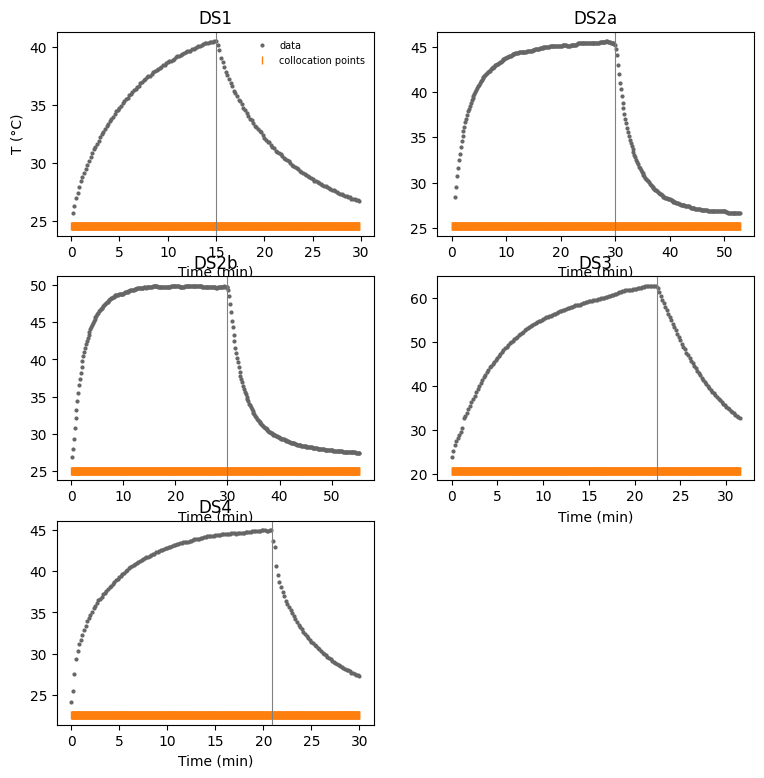

In [13]:
fig, ax = plt.subplots(3, 2, figsize=(9, 9))
for a, (label, ds) in zip(ax.ravel(), REAL_BY_LABEL.items()):
    t, T = load_real(ds)
    tc = np.linspace(0, 1, 800) * t.max()                      # the 800 collocation times
    a.plot(t / 60, T, "o", ms=2, color="0.4", label="data")
    a.plot(tc / 60, np.full_like(tc, T.min() - 0.08 * np.ptp(T)), "|", color="C1", label="collocation points")
    a.axvline(ds["t_off"] / 60, color="0.5", lw=0.8)
    a.set_title(label); a.set_xlabel("Time (min)")
ax[0, 0].set_ylabel("T (°C)"); ax[0, 0].legend(frameon=False, fontsize=7)
ax[2, 1].axis("off")                                          # five plots in a 3 x 2 grid
plt.savefig("results/plots/rev1_1_collocation.jpg", dpi=150, bbox_inches="tight"); plt.show()

## 2 · Training losses

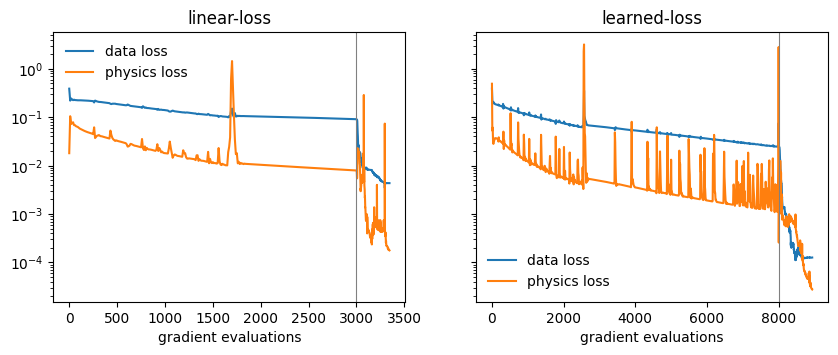

In [14]:
hist = logged_history("results/training_history.csv")
models = ["linear-loss", "learned-loss"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for a, m in zip(ax, models):
    h = hist[hist.model == m]
    a.semilogy(h.n_eval, h.data_loss, label="data loss"); a.semilogy(h.n_eval, h.physics_loss, label="physics loss")
    a.axvline(h.loc[h.phase == "L-BFGS", "n_eval"].min() - 1, color="0.5", lw=0.8)       # Adam ends, L-BFGS starts
    a.set_title(m); a.set_xlabel("gradient evaluations"); a.legend(frameon=False)
plt.savefig("results/plots/rev1_2_training_losses.jpg", dpi=150, bbox_inches="tight"); plt.show()

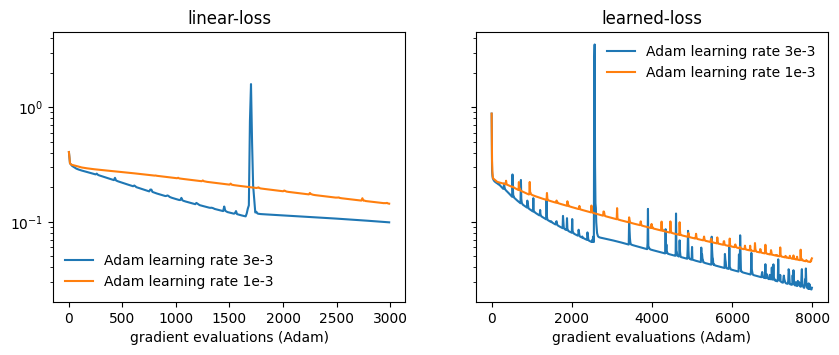

In [15]:
hist_lr = logged_history("results/rev1_history_adam_lr_1e-3.csv", adam_lr=1e-3)     # Adam learning rate 1e-3 instead of 3e-3
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for a, m in zip(ax, models):
    for name, hh in [("3e-3", hist), ("1e-3", hist_lr)]:
        h = hh[(hh.model == m) & (hh.phase == "Adam")]
        a.semilogy(h.n_eval, h.data_loss + h.physics_loss, label=f"Adam learning rate {name}")
    a.set_title(m); a.set_xlabel("gradient evaluations (Adam)"); a.legend(frameon=False)
plt.savefig("results/plots/rev1_2_adam_learning_rate.jpg", dpi=150, bbox_inches="tight"); plt.show()

## 3 · Gradient flow per layer

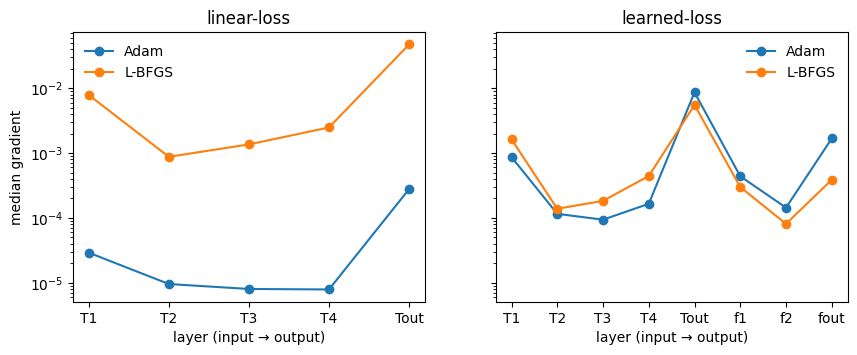

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for a, m in zip(ax, models):
    h = hist[hist.model == m]
    layers = [l for l in ["T1", "T2", "T3", "T4", "Tout", "f1", "f2", "fout"] if h[l].notna().any()]
    for phase in ["Adam", "L-BFGS"]:
        a.semilogy(layers, h[h.phase == phase][layers].median(), "o-", label=phase)
    a.set_title(m); a.set_xlabel("layer (input → output)"); a.legend(frameon=False)
ax[0].set_ylabel("median gradient")
plt.savefig("results/plots/rev1_3_gradient_flow.jpg", dpi=150, bbox_inches="tight"); plt.show()

## 4 · Budget step by step, validation loss

In [17]:
BUDGETS = [(1000, 100), (3000, 300), (8000, 1000), (16000, 2000)]         # (Adam steps, L-BFGS iterations)
names = [f"{a}+{b}" for a, b in BUDGETS]
rows = []
for label in ["DS1", "DS2b", "DS4"]:
    ds = REAL_BY_LABEL[label]
    t, T = load_real(ds)
    Te, toff = ds["Tenv"], ds["t_off"]
    val = np.arange(len(t)) % 5 == 4                                       # every 5th point is validation data
    val[-1] = False
    for adam, lbfgs in BUDGETS:
        with redirect_stdout(io.StringIO()):
            fit_lin = train_photothermal(t[~val], T[~val], toff, Tenv_=Te, adam_epochs=adam, lbfgs_iters=lbfgs, return_fit=True)[2] - Te
        fit_learn = train_loss_pinn(t[~val], T[~val] - Te, toff, adam_epochs=adam, lbfgs_iters=lbfgs)[2]
        for m, fit in [("linear-loss", fit_lin), ("learned-loss", fit_learn)]:
            tr, va = rms(fit, (T - Te)[~val]), rms(np.interp(t[val], t[~val], fit), (T - Te)[val])
            rows.append(dict(model=m, curve=label, budget=f"{adam}+{lbfgs}", rms=f"{tr:.2f} / {va:.2f}"))
df = pd.DataFrame(rows)
for m in models:
    print(f"{m} PINN: RMS in °C, training / validation")
    print(df[df.model == m].pivot(index="curve", columns="budget", values="rms")[names].to_string(), "\n")

linear-loss PINN: RMS in °C, training / validation
budget     1000+100     3000+300    8000+1000   16000+2000
curve                                                     
DS1     0.34 / 0.34  0.34 / 0.34  0.34 / 0.34  0.34 / 0.34
DS2b    1.82 / 1.83  1.69 / 1.70  1.62 / 1.63  1.62 / 1.63
DS4     0.95 / 1.00  0.94 / 0.99  0.94 / 0.99  0.94 / 0.99 

learned-loss PINN: RMS in °C, training / validation
budget     1000+100     3000+300    8000+1000   16000+2000
curve                                                     
DS1     0.23 / 0.23  0.23 / 0.23  0.23 / 0.23  0.23 / 0.22
DS2b    1.67 / 1.68  0.31 / 0.29  0.27 / 0.25  0.26 / 0.25
DS4     0.78 / 0.83  0.72 / 0.77  0.66 / 0.72  0.69 / 0.74 



## 5 · Curve-fitting methods

In [18]:
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
print(pd.DataFrame([
    ("Least squares (single_tau_fit)", "f = k θ, k = 1/τ", "a, k", "all points, least squares on the ODE solution"),
    ("Linear-loss PINN", "f = k θ", "a, τ", "Adam 3000 + L-BFGS 300, data loss + ODE residual"),
    ("Learned-loss PINN", "f = θ·softplus(h(θ)), h a small network", "a only (f is a network)", "Adam 8000 + L-BFGS 1000, data loss + ODE residual"),
], columns=["method", "law f(θ)", "estimated", "fitting"]).to_string(index=False))

                        method                                law f(θ)               estimated                                           fitting
Least squares (single_tau_fit)                        f = k θ, k = 1/τ                    a, k     all points, least squares on the ODE solution
              Linear-loss PINN                                 f = k θ                    a, τ  Adam 3000 + L-BFGS 300, data loss + ODE residual
             Learned-loss PINN f = θ·softplus(h(θ)), h a small network a only (f is a network) Adam 8000 + L-BFGS 1000, data loss + ODE residual


## 6 · Recovering k from the learned loss law

In [19]:
def recover_k(t, th, toff, seed):
    a, f, _ = train_loss_pinn(t, th, toff, seed=seed)
    x = np.linspace(0.1 * th.max(), th.max(), 50)
    return a, x @ f(x) / (x @ x)                          # least-squares fit of f = k θ to the learned f


for name, e in EXPERIMENTS.items():                       # synthetic linear loss: the true k is 1/τ
    ks = []
    for s in range(3):
        t, T = make_experiment(**e, seed=s)
        ks.append(recover_k(t, T - Tenv_true, e["t_off_e"], s)[1])
    k = np.mean(ks)
    print(f"{name}: true k = {1 / tau_true:.4g}, recovered k = {k:.4g} ({100 * (k * tau_true - 1):+.2f} %)")

curves = {}
for label, ds in REAL_BY_LABEL.items():                   # real curves: against the single-exponential fit
    t, T = load_real(ds)
    th, toff = T - ds["Tenv"], ds["t_off"]
    k_single = single_tau_fit(t, th, toff)[0][1]
    runs = [recover_k(t, th, toff, s) for s in range(3)]
    k = np.mean([r[1] for r in runs])
    print(f"{label}: recovered k = {k:.4g}, single-exponential fit k = {k_single:.4g} ({100 * (k / k_single - 1):+.2f} %)")
    curves[label] = (t, th, simulate_loss(t, runs[0][0], lambda x: runs[0][1] * x, toff))

full  (heat 5τ, cool 5τ): true k = 0.003333, recovered k = 0.003342 (+0.26 %)
short (heat 1τ, cool 2τ): true k = 0.003333, recovered k = 0.003312 (-0.64 %)
DS1: recovered k = 0.002652, single-exponential fit k = 0.002625 (+1.03 %)
DS2a: recovered k = 0.004481, single-exponential fit k = 0.004379 (+2.34 %)
DS2b: recovered k = 0.004592, single-exponential fit k = 0.004542 (+1.10 %)
DS3: recovered k = 0.002627, single-exponential fit k = 0.002652 (-0.95 %)
DS4: recovered k = 0.004628, single-exponential fit k = 0.004527 (+2.24 %)


## 7 · Quality of the recovered parameters

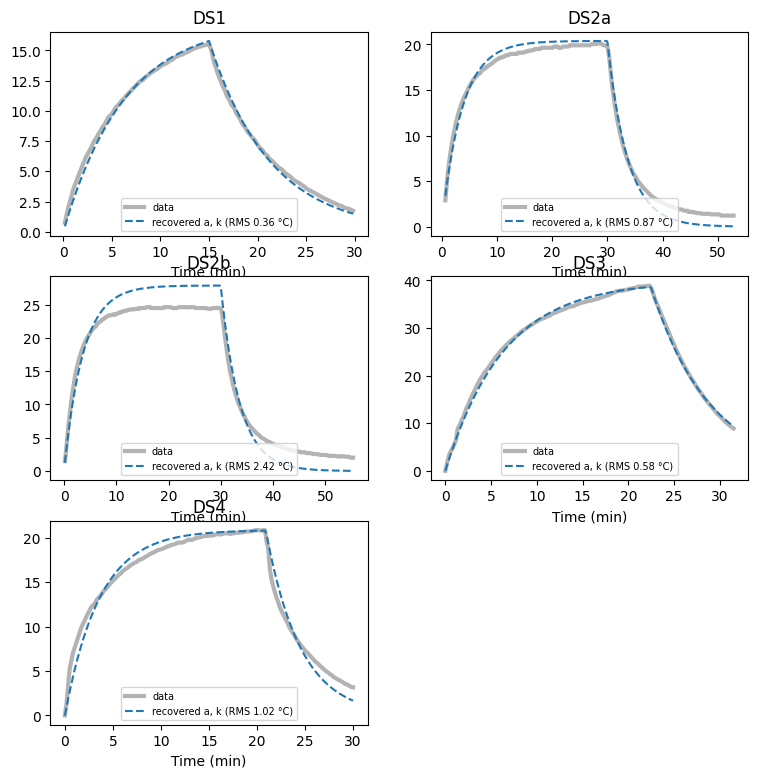

In [20]:
fig, ax = plt.subplots(3, 2, figsize=(9, 9))
for a, (label, (t, th, y)) in zip(ax.ravel(), curves.items()):
    a.plot(t / 60, th, color="0.7", lw=3, label="data")
    a.plot(t / 60, y, "--", label=f"recovered a, k (RMS {rms(y, th):.2f} °C)")
    a.set_title(label); a.set_xlabel("Time (min)"); a.legend(fontsize=7, loc="lower center")
ax[2, 1].axis("off")                                          # five plots in a 3 x 2 grid
plt.savefig("results/plots/rev1_6_recovered_parameters.jpg", dpi=150, bbox_inches="tight"); plt.show()